# BERT Model Evaluation & Inference
### Testing the fine-tuned `bert-base-uncased` model on unseen IMDB reviews



## Step 1 — Imports and Global Variables
Importing the necessary libraries for data manipulation, model loading, and defining the paths for our saved datasets and fine-tuned model.

In [ ]:
!pip install -q --upgrade datasets # Upgrade the 'datasets' library quietly (-q) to ensure compatibility

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 18.6 MB/s eta 0:00:00


In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_from_disk
from transformers import BertForSequenceClassification
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    classification_report
)

DEVICE          = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAVE_PATH       = "/content/drive/MyDrive/Licenta/tokenized_imdb"
MODEL_SAVE_PATH = "/content/drive/MyDrive/Licenta/best_model"
BATCH_SIZE      = 16

print(f"Device: {DEVICE}")
print("Imports done!")

Device: cuda
Imports done!


In [ ]:
# Import standard libraries for system operations and array manipulation
import torch
import numpy as np
from datasets import load_from_disk
from transformers import BertForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset

DEVICE          = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAVE_PATH       = "/content/drive/MyDrive/Licenta/tokenized_imdb"
MODEL_SAVE_PATH = "/content/drive/MyDrive/Licenta/best_model"
BATCH_SIZE      = 16 # Set the batch size for the evaluation dataloader

from google.colab import drive
drive.mount('/content/drive')

model = BertForSequenceClassification.from_pretrained(MODEL_SAVE_PATH)
model = model.to(DEVICE)
model.eval()

# Load and convert manually to TensorDataset
dataset = load_from_disk(SAVE_PATH)
dataset["test"] = dataset["test"].with_format(None)
test    = dataset["test"]

input_ids      = torch.tensor(np.array(test["input_ids"]),      dtype=torch.long)
attention_mask = torch.tensor(np.array(test["attention_mask"]), dtype=torch.long)
labels         = torch.tensor(np.array(test["labels"]),         dtype=torch.long)

test_dataset = TensorDataset(input_ids, attention_mask, labels)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Test samples : {len(test_dataset)}")
print(f"Test batches : {len(test_loader)}")
print("Ready!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Test samples : 7437
Test batches : 465
Ready!


## Step 2 — Batch Evaluation on Test Data
Iterating through the `test_loader` to gather model predictions for the entire test dataset without updating the model weights.

In [ ]:
# Initialize empty lists to store all model predictions and true labels
all_preds  = []
all_labels = []

# Disable gradient calculation to save memory and speed up evaluation
with torch.no_grad():
    for input_ids, attention_mask, labels in test_loader:
        input_ids      = input_ids.to(DEVICE)
        attention_mask = attention_mask.to(DEVICE)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask) # Forward pass: get the model's output (logits) for the current batch
        preds   = torch.argmax(outputs.logits, dim=1) # Get the predicted class by finding the index with the highest logit value

# Convert predictions and labels to NumPy arrays and append to our master lists
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(f"Done! {len(all_preds)} predictions")

Done! 7437 predictions


## Step 3 — Classification Report and Confusion Matrix Visualization


In [ ]:
accuracy  = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall    = recall_score(all_labels, all_preds)
f1        = f1_score(all_labels, all_preds)

print("=" * 45)
print("         FINAL TEST SET RESULTS")
print("=" * 45)
print(f"  Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"  Precision : {precision:.4f}  ({precision*100:.2f}%)")
print(f"  Recall    : {recall:.4f}  ({recall*100:.2f}%)")
print(f"  F1 Score  : {f1:.4f}  ({f1*100:.2f}%)")
print("=" * 45)

print("\nDetailed Classification Report:")
print(classification_report(
    all_labels, all_preds,
    target_names=["Negative", "Positive"]
))

         FINAL TEST SET RESULTS
  Accuracy  : 0.9414  (94.14%)
  Precision : 0.9440  (94.40%)
  Recall    : 0.9389  (93.89%)
  F1 Score  : 0.9414  (94.14%)

Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       0.94      0.94      0.94      3705
    Positive       0.94      0.94      0.94      3732

    accuracy                           0.94      7437
   macro avg       0.94      0.94      0.94      7437
weighted avg       0.94      0.94      0.94      7437



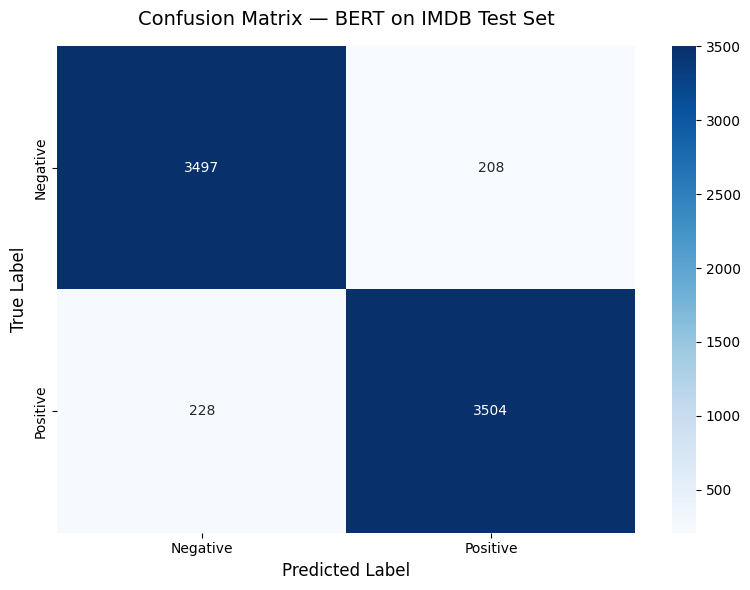

Confusion matrix saved to Drive!


In [ ]:
cm = confusion_matrix(all_labels, all_preds) # Calculate the confusion matrix based on the true labels and the model's predictions

plt.figure(figsize=(8, 6))
# Create a heatmap using seaborn to visualize the confusion matrix
sns.heatmap(
    cm,
    annot=True, # displays the numbers in the cells
    fmt="d", # formats them as integers
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
)
plt.title("Confusion Matrix — BERT on IMDB Test Set", fontsize=14, pad=15)
plt.ylabel("True Label", fontsize=12)
plt.xlabel("Predicted Label", fontsize=12)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Licenta/confusion_matrix.png", dpi=150)
plt.show()
print("Confusion matrix saved to Drive!")

## Step 4 — Data Preparation and Dataset Alignment


In [ ]:
from datasets import load_from_disk
import torch

SAVE_PATH = "/content/drive/MyDrive/Licenta/tokenized_imdb"
dataset   = load_from_disk(SAVE_PATH)

# Get raw texts from original dataset for error analysis
from datasets import load_dataset
raw_dataset = load_dataset("stanfordnlp/imdb")

# We need the original texts — rebuild test texts from raw data
# Use the same random state as preprocessing to align correctly
import pandas as pd
from sklearn.model_selection import train_test_split

# Load raw train and test splits into separate DataFrames
train_df = pd.DataFrame(raw_dataset["train"])
test_df  = pd.DataFrame(raw_dataset["test"])
df       = pd.concat([train_df, test_df], ignore_index=True)

# Function to remove HTML tags and extra whitespaces for clean data
import re
def clean_text(text):
    text = re.sub(r"<.*?>", " ", text) # Regex to find and remove all HTML tags
    text = re.sub(r"\s+", " ", text).strip() # Regex to find and replace multiple spaces with single space, then trim
    return text

df["text"] = df["text"].apply(clean_text) # Apply the clean_text function to every text entry in the DataFrame
df         = df.drop_duplicates(subset=["text"]).reset_index(drop=True) # Deduplicate text entries by content to prevent data leakage

_, test_split = train_test_split(
    df, test_size=0.15, random_state=42, stratify=df["label"]
)
test_texts  = test_split["text"].tolist()
test_labels = test_split["label"].tolist()
print(f"Test texts loaded: {len(test_texts)}")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Test texts loaded: 7437


## Step 5 - Calculate Evaluation Metrics and Error Rates

In [ ]:
wrong_indices  = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p != l] # Find the indices where the prediction (p) does not match the actual label (l)
correct_indices = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p == l] # Find the indices where the prediction (p) correctly matches the actual label (l)

# Map numerical labels to their human-readable string representations
label_map = {0: "Negative", 1: "Positive"}

print(f"Total errors   : {len(wrong_indices)} / {len(all_labels)}")
print(f"Error rate     : {len(wrong_indices)/len(all_labels)*100:.2f}%")
print(f"Correct        : {len(correct_indices)}")

Total errors   : 436 / 7437
Error rate     : 5.86%
Correct        : 7001


## Step 6 - Display Misclassified Examples

In [ ]:
print("=" * 70)
print("MISCLASSIFIED EXAMPLES")
print("=" * 70)

# Iterate through the first 5 indices of incorrectly predicted examples
for idx in wrong_indices[:5]:
    text       = test_texts[idx]
    true_label = label_map[all_labels[idx]]
    pred_label = label_map[all_preds[idx]]

    print(f"\nExample #{idx}")
    print(f"  True Label : {true_label}")
    print(f"  Predicted  : {pred_label}")
    print(f"  Text       : {text[:300]}...")
    print("-" * 70)

MISCLASSIFIED EXAMPLES

Example #67
  True Label : Negative
  Predicted  : Positive
  Text       : WE FAW DOWN Aspect ratio: 1.33:1 Sound format: Silent (Black and white - Short film) Stan 'n' Ollie get mixed up with a couple of floozies (Kay Deslys and Vera White) after setting out to visit a theatre which burns down in their absence! Needless to say, their tyrannical wives (Vivien Oakland and B...
----------------------------------------------------------------------

Example #87
  True Label : Negative
  Predicted  : Positive
  Text       : The volleyball genre is strangely overlooked by most screenwriters. Thankfully, highly acclaimed director Nelson McCormick has brought us the second best volleyball movie of all time (rated lower than Side Out and higher than, well, umm). However, don't let the cover of this movie decieve you. Kill ...
----------------------------------------------------------------------

Example #90
  True Label : Positive
  Predicted  : Negative
  Text       :

## Step 7 - Analyze and Plot Error Distribution by Review Length

Average length of WRONG predictions   : 265 words
Average length of CORRECT predictions : 227 words


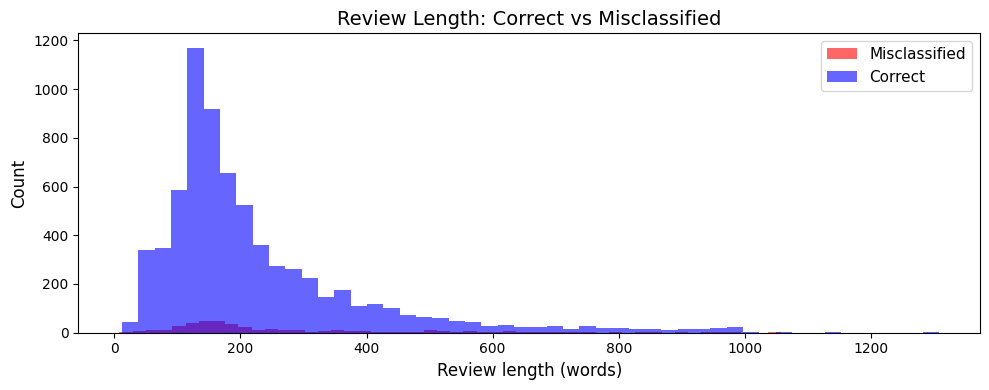

In [ ]:
# Check if longer reviews have more errors
wrong_lengths   = [len(test_texts[i].split()) for i in wrong_indices]
correct_lengths = [len(test_texts[i].split()) for i in correct_indices]

print(f"Average length of WRONG predictions   : {sum(wrong_lengths)/len(wrong_lengths):.0f} words")
print(f"Average length of CORRECT predictions : {sum(correct_lengths)/len(correct_lengths):.0f} words")

# Plot distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.hist(wrong_lengths,   bins=50, alpha=0.6, color="red",  label="Misclassified")
plt.hist(correct_lengths, bins=50, alpha=0.6, color="blue", label="Correct")
plt.xlabel("Review length (words)", fontsize=12)
plt.ylabel("Count",                 fontsize=12)
plt.title("Review Length: Correct vs Misclassified", fontsize=14)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Licenta/error_length_analysis.png", dpi=150)
plt.show()

## Step 8 - Analyze Impact of Irony and Sarcasm on Model Performance

In [ ]:
# Define a list of keywords commonly associated with irony or sarcasm
irony_keywords = [
    "supposedly", "apparently", "brilliant", "genius",
    "masterpiece", "wow", "amazing", "sure", "right",
    "of course", "obviously", "great job", "well done"
]

# Initialize empty lists to store indices of reviews with potential irony
irony_errors   = []
irony_correct  = []

# Iterate through indices of incorrectly classified reviews (errors)
for idx in wrong_indices:
    text_lower = test_texts[idx].lower() # Convert text to lowercase for case-insensitive keyword matching
    if any(kw in text_lower for kw in irony_keywords): # Check if any of the predefined irony keywords exist in the text
        irony_errors.append(idx)

# Iterate through indices of correctly classified reviews
for idx in correct_indices:
    text_lower = test_texts[idx].lower() # Convert text to lowercase for case-insensitive keyword matching
    if any(kw in text_lower for kw in irony_keywords): # Check if any of the predefined irony keywords exist in the text
        irony_correct.append(idx)

# Calculate the total number of reviews containing potential irony keywords
total_irony = len(irony_errors) + len(irony_correct)
print(f"Reviews with potential irony/sarcasm keywords : {total_irony}")
print(f"  Misclassified : {len(irony_errors)} "
      f"({len(irony_errors)/total_irony*100:.1f}%)")
print(f"  Correct       : {len(irony_correct)} "
      f"({len(irony_correct)/total_irony*100:.1f}%)")

print("\nExample of potentially ironic misclassified review:")
if irony_errors:
    idx  = irony_errors[0]
    print(f"  True: {label_map[all_labels[idx]]} | "
          f"Predicted: {label_map[all_preds[idx]]}")
    print(f"  Text: {test_texts[idx][:300]}...")

Reviews with potential irony/sarcasm keywords : 3382
  Misclassified : 208 (6.2%)
  Correct       : 3174 (93.8%)

Example of potentially ironic misclassified review:
  True: Negative | Predicted: Positive
  Text: WE FAW DOWN Aspect ratio: 1.33:1 Sound format: Silent (Black and white - Short film) Stan 'n' Ollie get mixed up with a couple of floozies (Kay Deslys and Vera White) after setting out to visit a theatre which burns down in their absence! Needless to say, their tyrannical wives (Vivien Oakland and B...
